In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/online_retail_clean.csv", parse_dates= ['InvoiceDate'])
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,Year,Month,Day,Hour,DayOfWeek,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34


In [38]:
df["CustomerID"].head(10)

0    17850.0
1    17850.0
2    17850.0
3    17850.0
4    17850.0
5    17850.0
6    17850.0
7    17850.0
8    17850.0
9    13047.0
Name: CustomerID, dtype: float64

#### we need to remove the rows with no customer id

In [39]:
from re import match
cust = df[df["CustomerID"].astype(str).str.match(r"^\d+(\.0)?$")].copy()
print(f"{len(df):,} rows -> {len(cust):,} rows with a real customer ID")

541,909 rows -> 406,829 rows with a real customer ID


In [40]:
cust.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,Year,Month,Day,Hour,DayOfWeek,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,False,2010,12,1,8,Wednesday,11.10
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,False,2010,12,1,8,Wednesday,54.08


#### groupby the customers for quantity of orders

In [41]:
customer_summary = cust.groupby("CustomerID").agg(
    TotalOrders   = ("InvoiceNo", "nunique"),
    TotalRevenue  = ("Revenue", "sum"),
    FirstPurchase = ("InvoiceDate", "min"),
    LastPurchase  = ("InvoiceDate", "max"),
).reset_index()

print(customer_summary.shape)
customer_summary.head()

(4372, 5)


,CustomerID,TotalOrders,TotalRevenue,FirstPurchase,LastPurchase
0,12346.0,2,0.00,2011-01-18 10:01:00,2011-01-18 10:17:00
1,12347.0,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00
2,12348.0,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00
3,12349.0,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00
4,12350.0,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00


In [42]:
customer_summary.to_csv("../data/processed/customer_summary.csv", index=False)

In [43]:
customer_summary

,CustomerID,TotalOrders,TotalRevenue,FirstPurchase,LastPurchase
0,12346.0,2,0.00,2011-01-18 10:01:00,2011-01-18 10:17:00
1,12347.0,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00
2,12348.0,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00
3,12349.0,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00
4,12350.0,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00
...,...,...,...,...,...
4367,18280.0,1,180.60,2011-03-07 09:52:00,2011-03-07 09:52:00
4368,18281.0,1,80.82,2011-06-12 10:53:00,2011-06-12 10:53:00
4369,18282.0,3,176.60,2011-08-05 13:35:00,2011-12-02 11:43:00
4370,18283.0,16,2094.88,2011-01-06 14:14:00,2011-12-06 12:02:00


In [44]:
top10 = customer_summary.nlargest(10,"TotalRevenue")
print(top10)

      CustomerID  TotalOrders  TotalRevenue       FirstPurchase  \
1703     14646.0           77     279489.02 2010-12-20 10:09:00   
4233     18102.0           62     256438.49 2010-12-07 16:42:00   
3758     17450.0           55     187482.17 2010-12-07 09:23:00   
1895     14911.0          248     132572.62 2010-12-01 14:05:00   
55       12415.0           26     123725.45 2011-01-06 11:12:00   
1345     14156.0           66     113384.14 2010-12-02 17:08:00   
3801     17511.0           46      88125.38 2010-12-01 10:19:00   
3202     16684.0           31      65892.08 2010-12-16 17:34:00   
1005     13694.0           60      62653.10 2010-12-01 12:12:00   
2192     15311.0          118      59419.34 2010-12-01 09:41:00   

            LastPurchase  
1703 2011-12-08 12:12:00  
4233 2011-12-09 11:50:00  
3758 2011-12-01 13:29:00  
1895 2011-12-08 15:54:00  
55   2011-11-15 14:22:00  
1345 2011-11-30 10:54:00  
3801 2011-12-07 10:12:00  
3202 2011-12-05 14:06:00  
1005 2011-12-06 09:

In [45]:
total_rev = customer_summary['TotalRevenue'].sum()
share = top10['TotalRevenue'].sum() / total_rev *100
print(f"Top 10 customers = {share:.1f}% of all revenue")

Top 10 customers = 16.5% of all revenue


In [46]:
one_time = (customer_summary["TotalOrders"] == 1).mean() * 100
repeat = (customer_summary['TotalOrders'] > 1).mean() * 100

print(f"One-time buyers: {one_time:.1f}%")
print(f"Repeat buyers: {repeat:.1f}%")

One-time buyers: 30.0%
Repeat buyers: 70.0%


In [47]:
print(customer_summary["TotalOrders"].describe())

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: TotalOrders, dtype: float64


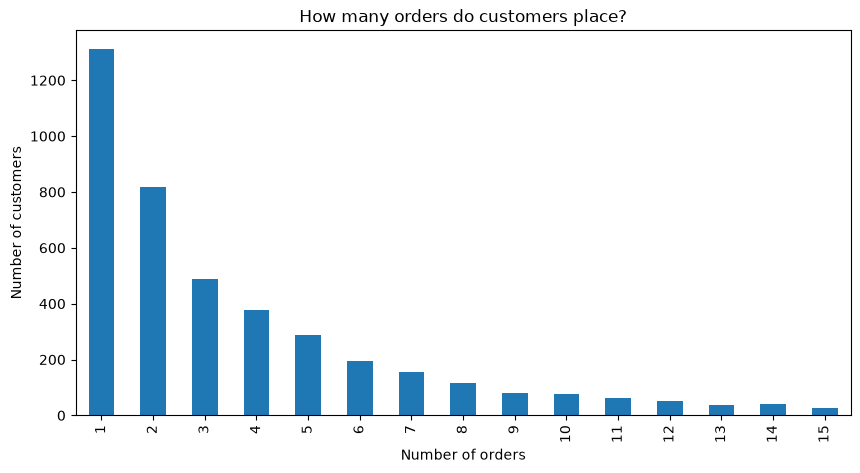

In [48]:
customer_summary["TotalOrders"].value_counts().sort_index().head(15).plot(kind="bar", figsize=(10,5))
plt.title("How many orders do customers place?")
plt.xlabel("Number of orders")
plt.ylabel("Number of customers")
plt.savefig("../reports/figures/orders_per_customer.png", dpi=150)
plt.show()

In [49]:
SNAPSHOT = cust["InvoiceDate"].max()
print("Snapshot date:", SNAPSHOT.date())

Snapshot date: 2011-12-09


In [50]:
rfm = customer_summary.copy()

rfm['Recency'] = (SNAPSHOT - rfm['LastPurchase']).dt.days

rfm["Frequency"] = rfm["TotalOrders"]
rfm["Monetary"] = rfm["TotalRevenue"]

rfm[['CustomerID', "Recency", "Frequency", "Monetary"]].head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,2,0.00
1,12347.0,1,7,4310.00
2,12348.0,74,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,309,1,334.40


In [52]:
# Rank the values first to ensure unique edges, then qcut
rfm["M_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["R_score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)


In [53]:
rfm["R_score"] = 6 - rfm["R_score"]


In [54]:
recent = rfm.nsmallest(3, "Recency")
print(recent[["CustomerID", "Recency", "R_score"]])

     CustomerID  Recency  R_score
61      12423.0        0        5
71      12433.0        0        5
105     12476.0        0        5


In [55]:
def segment(row):
    if row.R_score >= 4 and row.F_score >= 4 and row.M_score >= 4: return "Champions"
    if row.R_score <= 2 and row.F_score >= 3:                       return "At Risk"
    if row.R_score >= 3 and row.F_score <= 2:                       return "New Customers"
    if row.R_score <= 2 and row.F_score <= 2:                       return "Lost"
    return "Regular"

rfm["Segment"] = rfm.apply(segment, axis=1)

In [56]:
seg = rfm.groupby("Segment").agg(
    Customers = ("CustomerID", "count"),
    Revenue   = ("Monetary", "sum"),
).assign(
    pct_customers = lambda x: (x.Customers / x.Customers.sum() * 100).round(1),
    pct_revenue   = lambda x: (x.Revenue / x.Revenue.sum() * 100).round(1),
).sort_values("Revenue", ascending=False)

print(seg)

               Customers      Revenue  pct_customers  pct_revenue
Segment                                                          
Champions            964  5620812.180           22.0         67.7
Regular              970  1231429.631           22.2         14.8
At Risk              689   756019.582           15.8          9.1
Lost                1060   398791.571           24.2          4.8
New Customers        689   293012.850           15.8          3.5


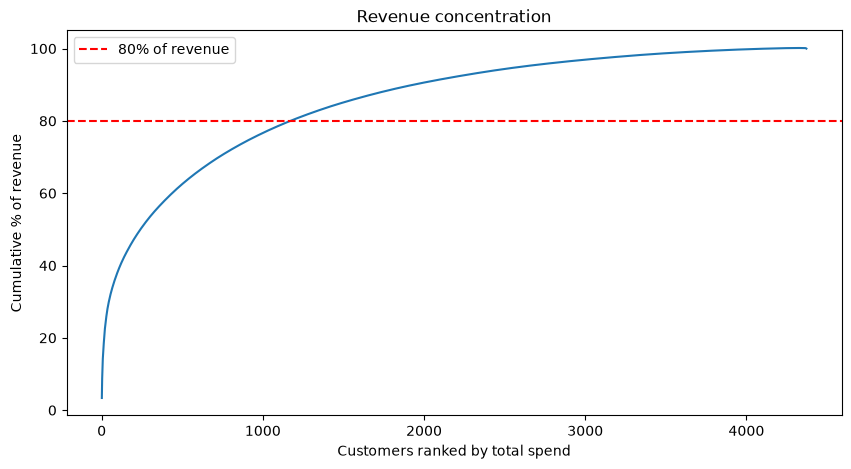

In [58]:
s = rfm["Monetary"].sort_values(ascending=False)
cum = s.cumsum() / s.sum() * 100

plt.figure(figsize=(10,5))
plt.plot(range(1, len(s)+1), cum)
plt.axhline(80, color="red", ls="--", label="80% of revenue")
plt.xlabel("Customers ranked by total spend")
plt.ylabel("Cumulative % of revenue")
plt.title("Revenue concentration")
plt.legend()
plt.savefig("../reports/figures/revenue_concentration.png", dpi=150)
plt.show()